# Elo tuning

Week 2 loose end: `compute_elo_ratings` shipped with placeholder settings
(K=20, home advantage=60, summer regression=0.33). This notebook picks them
with data instead.

**How we score a setting:** Elo's expected score for the home team (e.g. 0.62)
against what actually happened (1 = home win, 0.5 = draw, 0 = away win), as a
mean squared error (a Brier score). Lower is better.

**Why this is leak-free on the training seasons:** each match's pre-match
rating is built only from earlier matches, so Elo's expected score is a
genuine out-of-sample prediction for that match. We score only the training
seasons (2016-17 to 2023-24). 2015-16 is warm-up, and the validation (2024-25)
and test (2025-26) seasons are never looked at here.

In [1]:
import sys
sys.path.insert(0, "..")

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.features.build_features import compute_elo_ratings

sns.set_theme(style="whitegrid")
matches = pd.read_csv("../data/processed/matches.csv", parse_dates=["date"])
TRAIN_SEASONS = [f"20{y}-{y + 1}" for y in range(16, 24)]   # 2016-17 .. 2023-24
ACTUAL = {"H": 1.0, "D": 0.5, "A": 0.0}
train_mask = matches["season"].isin(TRAIN_SEASONS)
print(f"{len(matches)} matches loaded, {train_mask.sum()} scored (training seasons)")

4180 matches loaded, 3040 scored (training seasons)


## Scoring function

In [2]:
def elo_brier(k, home_advantage, season_regression):
    """Brier score of Elo's pre-match expected score on the training seasons."""
    rated = compute_elo_ratings(matches, k=k, home_advantage=home_advantage,
                                season_regression=season_regression)
    expected = 1 / (1 + 10 ** ((rated["away_elo"] - (rated["home_elo"] + home_advantage)) / 400))
    actual = rated["result"].map(ACTUAL)
    return ((expected - actual)[train_mask] ** 2).mean()

# Reference point: always predict the average home score from the training seasons
# (no Elo at all). Any useful setting should beat this comfortably.
avg_actual = matches.loc[train_mask, "result"].map(ACTUAL)
no_skill = ((avg_actual.mean() - avg_actual) ** 2).mean()
current = elo_brier(20, 60, 0.33)
print(f"No-skill Brier (constant prediction): {no_skill:.4f}")
print(f"Current defaults (K=20, HA=60, reg=0.33): {current:.4f}")

No-skill Brier (constant prediction): 0.1892
Current defaults (K=20, HA=60, reg=0.33): 0.1570


## Grid search

In [3]:
K_VALUES = [10, 15, 20, 25, 30, 35, 40]
HA_VALUES = [30, 45, 60, 75, 90, 105]
REG_VALUES = [0.0, 0.2, 0.33, 0.5, 0.67, 1.0]   # 1.0 = full reset every summer

results = pd.DataFrame(
    [{"k": k, "home_advantage": ha, "season_regression": reg, "brier": elo_brier(k, ha, reg)}
     for k, ha, reg in itertools.product(K_VALUES, HA_VALUES, REG_VALUES)]
).sort_values("brier").reset_index(drop=True)
results.head(10)

,k,home_advantage,season_regression,brier
0,20,60,0.0,0.155362
1,25,60,0.0,0.155388
2,20,45,0.0,0.155452
3,25,45,0.0,0.155519
4,25,60,0.2,0.155587
5,25,45,0.2,0.155623
6,30,60,0.0,0.155663
7,30,60,0.2,0.155690
8,30,45,0.2,0.155776
9,15,60,0.0,0.155784


## How flat is the top?

If many settings score almost the same, the exact pick matters little, and a round, explainable number near the best is fine.

In [4]:
best = results.iloc[0]
print(f"Best: K={best.k:.0f}, HA={best.home_advantage:.0f}, reg={best.season_regression}, Brier={best.brier:.4f}")
print(f"Gain over current defaults: {current - best.brier:.4f}  "
      f"({(current - best.brier) / (no_skill - current):.1%} of current Elo's improvement over no-skill)")
print(f"Settings within 0.0005 of best: {(results.brier <= best.brier + 0.0005).sum()} of {len(results)}")

Best: K=20, HA=60, reg=0.0, Brier=0.1554
Gain over current defaults: 0.0016  (5.0% of current Elo's improvement over no-skill)
Settings within 0.0005 of best: 14 of 252


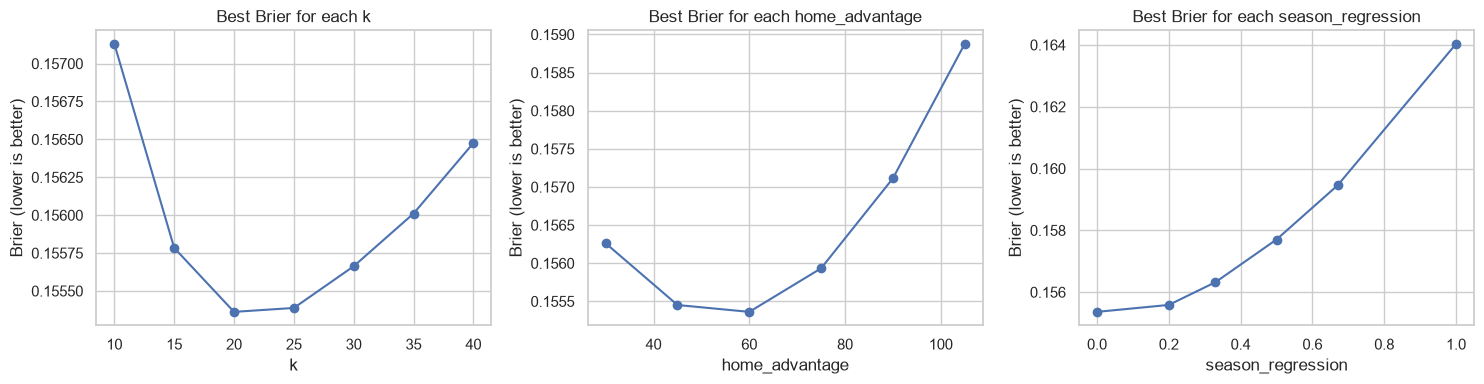

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, param in zip(axes, ["k", "home_advantage", "season_regression"]):
    results.groupby(param)["brier"].min().plot(ax=ax, marker="o")
    ax.set_title(f"Best Brier for each {param}")
    ax.set_ylabel("Brier (lower is better)")
plt.tight_layout()

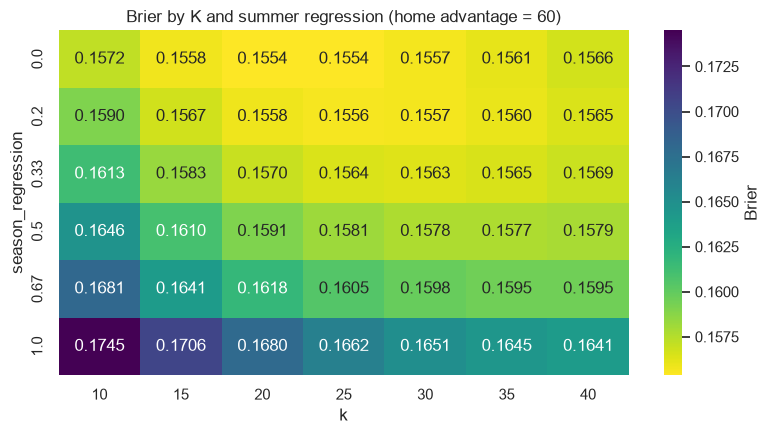

In [6]:
at_best_ha = results[results.home_advantage == best.home_advantage]
grid = at_best_ha.pivot(index="season_regression", columns="k", values="brier")
plt.figure(figsize=(8, 4.5))
sns.heatmap(grid, annot=True, fmt=".4f", cmap="viridis_r", cbar_kws={"label": "Brier"})
plt.title(f"Brier by K and summer regression (home advantage = {best.home_advantage:.0f})")
plt.tight_layout()

## Interpretation

- We chose k = 20, home_advantage = 60, and r = 0.0 because together they had the best Brier score. These were the exact best settings, and they happen to be round numbers. The top is flat (14 of 252 settings scored within 0.0005 of the best), so the exact pick matters little.

- K = 20 sits toward the slow end of the 10–40 range tested. A home win between two equal teams moves each rating by about 8 points. K = 10 was too sluggish to track real changes, and K = 40 chased random results.

- The chosen regression of 0.0 means a team carries its rating from the past season into the new season with no change over the summer.

- Given we already had the best K and home_advantage placeholders, the only setting that changed was the regression. Moving from 0.33 (assuming some drop-off over the summer) to 0.0 (assuming ratings carry over) improved the Brier score by 0.0016. That's about 5% of Elo's improvement over a no-skill prediction, so it's small: tuning confirmed the placeholders rather than transforming the model.